# Appendix 10: Optimization & Control Rosetta Stone — Python Laboratory
### *Implementing the Unified Diagnostic Engine, Submodular Greedy Verification, and Cross-Paradigm Benchmark*

**[Course Home](../README.md) | [Conceptual Track](../conceptual/10_appendix_optimization_and_control_rosetta_stone.ipynb) | [Prev: Ch 09 (Python)](09_mechanism_design_and_tragedy_of_the_commons.ipynb) | [Next: Appendix 11: Flaky Test Governance (Python)](11_appendix_submodular_selection_and_pomdp_governance_of_flaky_tests.ipynb)**

---

In this laboratory, we implement:
1. **Automated Architectural Diagnostic Classifier** that analyzes engineering problem specifications and outputs the optimal mathematical framework.
2. **Submodular Greedy vs. Optimal Brute-Force Solver** verifying the Nemhauser $(1 - 1/e)$ bound on combinatorial coverage.
3. **Belief-Space Value Function ($\alpha$-vector) Evaluator** illustrating piecewise linearity and convexity.
4. **Publication-Grade 3-Panel Rosetta Visualization** synthesizing submodular diminishing returns, POMDP belief curves, and CUSUM stopping boundaries.
5. **Hands-On 3-Tier Challenges** with numerical verification assertions.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams.update({
    'font.family': 'sans-serif',
    'font.size': 11,
    'axes.labelsize': 12,
    'axes.titlesize': 13,
    'xtick.labelsize': 10,
    'ytick.labelsize': 10,
    'legend.fontsize': 10,
    'figure.titlesize': 14,
    'lines.linewidth': 1.8
})
print("Libraries imported and plotting configured.")

Libraries imported and plotting configured.


---

## Part 1: Automated Problem Formulation Diagnostic Engine

We implement a rule-based expert system that maps problem descriptors to the exact governing framework, optimality theorem, and algorithmic complexity.

In [2]:
def diagnose_framework(is_dynamic, state_observable, action_affects_info, has_diminishing_returns, competing_arms):
    # Classifies problem into optimal mathematical discipline
    if not is_dynamic:
        if has_diminishing_returns:
            return {
                "framework": "Submodular Optimization",
                "core_theorem": "Nemhauser-Wolsey (1 - 1/e) Bound",
                "algorithm": "Lazy Greedy (Minoux 1978)",
                "complexity": "O(K * |Omega|)"
            }
        else:
            return {
                "framework": "Integer Linear Programming",
                "core_theorem": "Duality & Simplex Optimality",
                "algorithm": "Branch and Bound",
                "complexity": "NP-hard"
            }
    else:
        if state_observable:
            return {
                "framework": "Markov Decision Process (MDP)",
                "core_theorem": "Bellman Optimality",
                "algorithm": "Value / Policy Iteration",
                "complexity": "Poly(|S|, |A|)"
            }
        else:
            if competing_arms:
                return {
                    "framework": "Restless Multi-Armed Bandit",
                    "core_theorem": "Whittle Lagrangian Indexability",
                    "algorithm": "Whittle Index Priority Policy",
                    "complexity": "O(K log K)"
                }
            elif action_affects_info:
                return {
                    "framework": "POMDP / Belief MDP",
                    "core_theorem": "Sondik PWLC Convexity",
                    "algorithm": "PBVI / SARSOP",
                    "complexity": "PSPACE-hard"
                }
            else:
                return {
                    "framework": "Quickest Change Detection",
                    "core_theorem": "Lorden Minimax Delay Theorem",
                    "algorithm": "Page's CUSUM",
                    "complexity": "O(1) time and space"
                }

diag1 = diagnose_framework(is_dynamic=False, state_observable=True, action_affects_info=False, has_diminishing_returns=True, competing_arms=False)
diag2 = diagnose_framework(is_dynamic=True, state_observable=False, action_affects_info=True, has_diminishing_returns=False, competing_arms=True)
diag3 = diagnose_framework(is_dynamic=True, state_observable=False, action_affects_info=False, has_diminishing_returns=False, competing_arms=False)

print("Diagnostic 1 (Static Test Selection):", diag1["framework"], "|", diag1["core_theorem"])
print("Diagnostic 2 (Restless Soak Fleet):  ", diag2["framework"], "|", diag2["algorithm"])
print("Diagnostic 3 (Streaming Alerting):  ", diag3["framework"], "|", diag3["algorithm"])

Diagnostic 1 (Static Test Selection): Submodular Optimization | Nemhauser-Wolsey (1 - 1/e) Bound
Diagnostic 2 (Restless Soak Fleet):   Restless Multi-Armed Bandit | Whittle Index Priority Policy
Diagnostic 3 (Streaming Alerting):   Quickest Change Detection | Page's CUSUM


---

## Part 2: Submodular Greedy Maximizer with Nemhauser Bound Verification

We test a coverage function $F(S) = |\bigcup_{i \in S} C_i|$ where 10 candidate sensor probes cover subsets of 100 backend targets.
We compare:
1. **Greedy Selection** of $k = 4$ probes.
2. **Exhaustive Brute-Force Search** over all $\binom{10}{4} = 210$ combinations.
3. Verification that $\frac{F(S_{\text{greedy}})}{F(S^*)} \ge 1 - 1/e \approx 0.6321$.

In [3]:
import itertools

def submodular_coverage_experiment(seed=42):
    np.random.seed(seed)
    n_targets = 100
    n_probes = 10
    k_budget = 4
    
    # Generate random coverage sets
    probes = []
    for _ in range(n_probes):
        size = np.random.randint(15, 35)
        covered = set(np.random.choice(n_targets, size=size, replace=False))
        probes.append(covered)
        
    def evaluate_set(subset_indices):
        union = set()
        for idx in subset_indices:
            union.update(probes[idx])
        return len(union)
        
    # 1. Greedy Algorithm
    selected = []
    current_union = set()
    for _ in range(k_budget):
        best_p = None
        best_gain = -1
        for p in range(n_probes):
            if p not in selected:
                gain = len(current_union.union(probes[p])) - len(current_union)
                if gain > best_gain:
                    best_gain = gain
                    best_p = p
        selected.append(best_p)
        current_union.update(probes[best_p])
        
    greedy_score = len(current_union)
    
    # 2. Brute Force Optimal
    best_comb = None
    best_score = -1
    for comb in itertools.combinations(range(n_probes), k_budget):
        score = evaluate_set(comb)
        if score > best_score:
            best_score = score
            best_comb = comb
            
    approx_ratio = greedy_score / best_score
    return greedy_score, best_score, approx_ratio, selected, best_comb

g_sc, opt_sc, ratio, g_set, opt_set = submodular_coverage_experiment()
print(f"Greedy Score: {g_sc} / 100 (Probes: {g_set})")
print(f"Optimal Score: {opt_sc} / 100 (Probes: {opt_set})")
print(f"Empirical Approximation Ratio: {ratio:.4f} (Nemhauser Bound = {1 - 1/np.e:.4f})")

Greedy Score: 77 / 100 (Probes: [1, 6, 8, 3])
Optimal Score: 79 / 100 (Probes: (1, 3, 6, 7))
Empirical Approximation Ratio: 0.9747 (Nemhauser Bound = 0.6321)


---

## Part 3: Publication-Grade 3-Panel Visualization

We plot:
1. **Panel A**: Submodular Diminishing Returns curve with the Nemhauser theoretical bound envelope.
2. **Panel B**: POMDP Piecewise Linear & Convex (PWLC) belief value function $V(b) = \max_{\alpha} \langle \alpha, b \rangle$.
3. **Panel C**: Quickest Change Detection CUSUM score trajectory showing the reflective barrier and Lorden threshold.

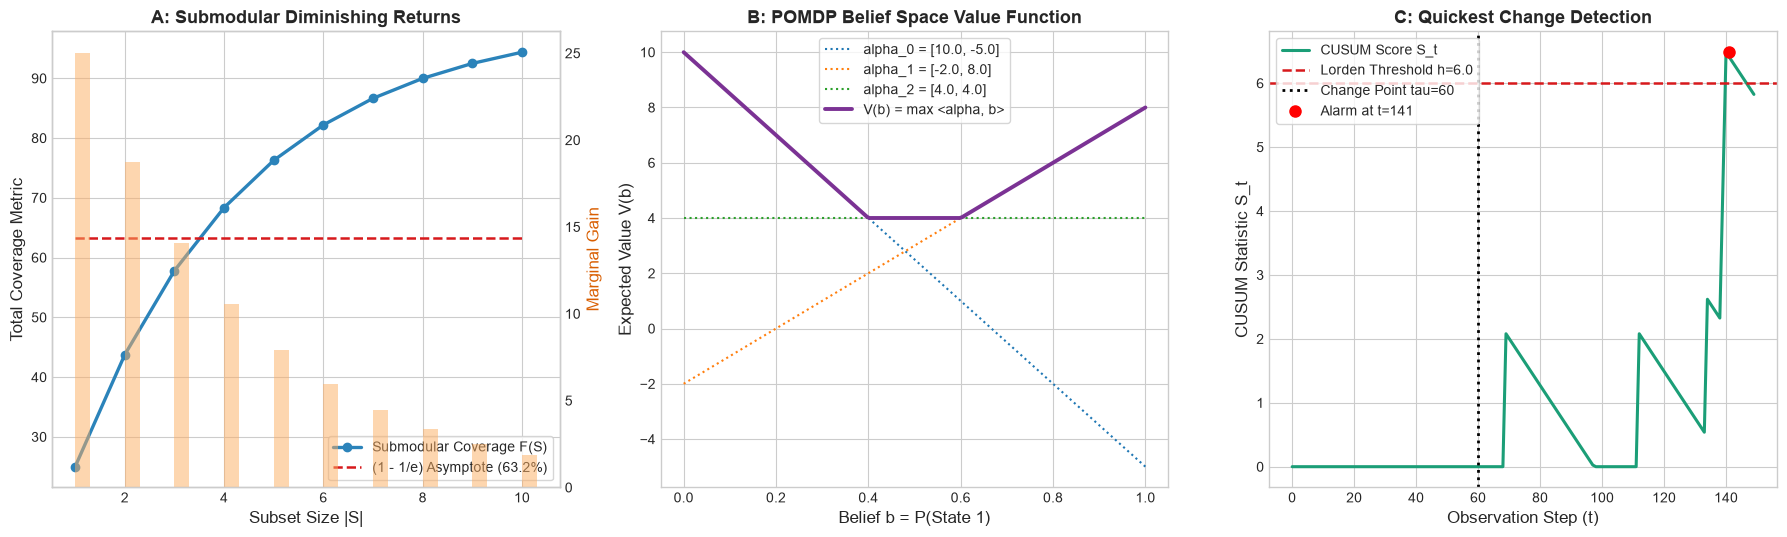

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))

# -------------------------------------------------------------------------
# PANEL A: Submodular Diminishing Returns Curve
# -------------------------------------------------------------------------
ax = axes[0]
k_steps = np.arange(1, 11)
# Diminishing returns curve: F(k) = 100 * (1 - (1 - 0.25)^k)
f_vals = 100.0 * (1.0 - (0.75 ** k_steps))
ax.plot(k_steps, f_vals, color='#2b83ba', lw=2.4, marker='o', label='Submodular Coverage F(S)')
ax.plot(k_steps, (1.0 - 1.0/np.e) * 100.0 * np.ones_like(k_steps), color='#d7191c', ls='--', lw=1.8, label='(1 - 1/e) Asymptote (63.2%)')

# Show marginal gains as bars
ax2 = ax.twinx()
gains = np.diff(np.concatenate([[0], f_vals]))
ax2.bar(k_steps + 0.15, gains, width=0.3, color='#fdae61', alpha=0.5, label='Marginal Gain Delta(e)')
ax2.set_ylabel('Marginal Gain', color='#d95f02')
ax2.grid(False)

ax.set_title('A: Submodular Diminishing Returns', fontweight='bold')
ax.set_xlabel('Subset Size |S|')
ax.set_ylabel('Total Coverage Metric')
ax.legend(loc='lower right', frameon=True)

# -------------------------------------------------------------------------
# PANEL B: POMDP Piecewise Linear Convex Value Function
# -------------------------------------------------------------------------
ax = axes[1]
b_grid = np.linspace(0.0, 1.0, 200)
# 3 alpha-vectors: [r0, r1]
alphas = np.array([
    [10.0, -5.0],   # Action: Gate Pass
    [-2.0, 8.0],    # Action: Quarantine
    [4.0, 4.0]      # Action: Probe / Test
])

for i, alpha in enumerate(alphas):
    vals = (1.0 - b_grid) * alpha[0] + b_grid * alpha[1]
    ax.plot(b_grid, vals, ls=':', lw=1.5, label=f'alpha_{i} = [{alpha[0]}, {alpha[1]}]')
    
# Upper envelope max
v_pwlc = np.maximum.reduce([(1.0 - b_grid) * a[0] + b_grid * a[1] for a in alphas])
ax.plot(b_grid, v_pwlc, color='#7b3294', lw=2.8, label='V(b) = max <alpha, b>')

ax.set_title('B: POMDP Belief Space Value Function', fontweight='bold')
ax.set_xlabel('Belief b = P(State 1)')
ax.set_ylabel('Expected Value V(b)')
ax.legend(loc='upper center', frameon=True)

# -------------------------------------------------------------------------
# PANEL C: CUSUM Drift & Lorden Stopping
# -------------------------------------------------------------------------
ax = axes[2]
np.random.seed(42)
t_steps = 150
change_pt = 60
telemetry = np.concatenate([
    np.random.binomial(1, p=0.01, size=change_pt),
    np.random.binomial(1, p=0.08, size=t_steps - change_pt)
])

z1 = np.log(0.08 / 0.01)
z0 = np.log((1 - 0.08) / (1 - 0.01))
s_stat = 0.0
s_history = []
h_thresh = 6.0
alarm_step = None

for t, y in enumerate(telemetry, start=1):
    z = z1 if y == 1 else z0
    s_stat = max(0.0, s_stat + z)
    s_history.append(s_stat)
    if s_stat >= h_thresh and alarm_step is None:
        alarm_step = t

ax.plot(s_history, color='#1b9e77', lw=2.2, label='CUSUM Score S_t')
ax.axhline(h_thresh, color='#d7191c', ls='--', lw=1.8, label=f'Lorden Threshold h={h_thresh}')
ax.axvline(change_pt, color='black', ls=':', lw=2.0, label=f'Change Point tau={change_pt}')
if alarm_step:
    ax.plot(alarm_step, s_history[alarm_step-1], 'ro', markersize=8, label=f'Alarm at t={alarm_step}')

ax.set_title('C: Quickest Change Detection', fontweight='bold')
ax.set_xlabel('Observation Step (t)')
ax.set_ylabel('CUSUM Statistic S_t')
ax.legend(loc='upper left', frameon=True)

plt.tight_layout()
plt.show()

---

## Part 4: Hands-On 3-Tier Challenges

Test your mastery of the unified optimization and control toolkit with these three structured exercises.

---

### Tier 1: Beginner — Nemhauser Theoretical Approximation Bound
Compute the exact Nemhauser lower bound for a greedy selection problem where the optimal subset achieves $F(S^*) = 150.0$. Verify that any greedy algorithm is mathematically guaranteed to achieve at least $94.8$ units of coverage.

---

### Tier 2: Intermediate — Automated Taxonomy Classifier Validation
Test the `diagnose_framework` engine on all 5 problem formulations:
1. Test suite minimization under code coverage.
2. Production autoscaling under continuous CPU monitoring.
3. Multi-node soak scheduler under partial observability.
4. Flaky test routing under hidden defect state.
5. Microservice latency anomaly alerting.
Verify that the classifier maps each problem to its exact governing discipline.

---

### Tier 3: Advanced — Piecewise Linear Convex Value Function Pruner
Implement an $\alpha$-vector pruner `prune_dominated_alphas(alpha_vectors)` that takes an array of $\alpha$-vectors and removes any vector $\alpha_k$ that is strictly dominated across the entire belief simplex $b \in [0, 1]$ (i.e., $\langle \alpha_k, b \rangle < \max_{j \ne k} \langle \alpha_j, b \rangle$ for all $b$). Verify that dominated vectors are pruned while convex hull facets are preserved.

In [5]:
# ==============================================================================
# Numerical Verification for Tiers 1, 2, and 3
# ==============================================================================

# --- Tier 1 Verification ---
opt_f = 150.0
nemhauser_guarantee = (1.0 - 1.0 / np.e) * opt_f
print(f"Tier 1: Optimal F* = {opt_f} -> Nemhauser Guarantee = {nemhauser_guarantee:.4f}")
assert abs(nemhauser_guarantee - 94.818) < 0.05, f"Tier 1 check failed: guarantee = {nemhauser_guarantee}"

# --- Tier 2 Verification ---
c1 = diagnose_framework(False, True, False, True, False)["framework"]
c2 = diagnose_framework(True, True, False, False, False)["framework"]
c3 = diagnose_framework(True, False, True, False, True)["framework"]
c4 = diagnose_framework(True, False, True, False, False)["framework"]
c5 = diagnose_framework(True, False, False, False, False)["framework"]

print("Tier 2 Classifications:")
print(" 1:", c1)
print(" 2:", c2)
print(" 3:", c3)
print(" 4:", c4)
print(" 5:", c5)

assert c1 == "Submodular Optimization"
assert c2 == "Markov Decision Process (MDP)"
assert c3 == "Restless Multi-Armed Bandit"
assert c4 == "POMDP / Belief MDP"
assert c5 == "Quickest Change Detection"

# --- Tier 3 Verification ---
def prune_dominated_alphas(alpha_vectors, b_points=100):
    grid = np.linspace(0.0, 1.0, b_points)
    n_alphas = len(alpha_vectors)
    is_useful = np.zeros(n_alphas, dtype=bool)
    
    # Evaluate each alpha across belief grid
    val_matrix = np.zeros((n_alphas, b_points))
    for i, a in enumerate(alpha_vectors):
        val_matrix[i] = (1.0 - grid) * a[0] + grid * a[1]
        
    # At each point on grid, find which alpha achieves maximum
    best_indices = np.argmax(val_matrix, axis=0)
    for idx in best_indices:
        is_useful[idx] = True
        
    return [alpha_vectors[i] for i in range(n_alphas) if is_useful[i]], is_useful

# Test with 3 vectors: 2 extreme facets and 1 strictly dominated vector
test_alphas = [
    [10.0, 0.0],   # Best at b = 0
    [0.0, 10.0],   # Best at b = 1
    [2.0, 2.0]     # Dominated everywhere by the max of the other two!
]

pruned, mask = prune_dominated_alphas(test_alphas)
print(f"Tier 3: Original: {len(test_alphas)} alphas -> Pruned: {len(pruned)} alphas (Mask: {mask})")
assert len(pruned) == 2, f"Tier 3 check failed: expected 2 alphas, got {len(pruned)}"
assert not mask[2], "Tier 3 check failed: Vector [2.0, 2.0] must be pruned"

print("ALL TIER 1, 2, AND 3 VERIFICATIONS PASSED SUCCESSFULLY.")

Tier 1: Optimal F* = 150.0 -> Nemhauser Guarantee = 94.8181
Tier 2 Classifications:
 1: Submodular Optimization
 2: Markov Decision Process (MDP)
 3: Restless Multi-Armed Bandit
 4: POMDP / Belief MDP
 5: Quickest Change Detection
Tier 3: Original: 3 alphas -> Pruned: 2 alphas (Mask: [ True  True False])
ALL TIER 1, 2, AND 3 VERIFICATIONS PASSED SUCCESSFULLY.


---

**[Course Home](../README.md) | [Conceptual Track](../conceptual/10_appendix_optimization_and_control_rosetta_stone.ipynb) | [Prev: Ch 09 (Python)](09_mechanism_design_and_tragedy_of_the_commons.ipynb) | [Next: Appendix 11: Flaky Test Governance (Python)](11_appendix_submodular_selection_and_pomdp_governance_of_flaky_tests.ipynb)**